In [8]:
# imports : 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV , KFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib 

In [3]:
%run ./2_transformatioNpreparation.ipynb

In [4]:
# defining models and their hyper params 


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    )
}


params = [
    
    {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs"],
    "model__class_weight": [None, "balanced"]
    }, 
    {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [5, 10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__class_weight": [None, "balanced"]
    }, 
    {"model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
    }, {
        
    }
]

In [5]:
# Start training  . 
best_models = {}
results = {}
k = KFold(n_splits=5 , shuffle=False)


for (model_name , model) , param in zip(models.items(), params) : 
    
    pipeline = Pipeline(
        [
            ("processer", preprocessor), 
            ("model" , model)
        ]
    )     
    grid = GridSearchCV(
        estimator=pipeline , 
        cv=k,
        param_grid=param,
        scoring="f1_macro",
        n_jobs=-1,       
    )
    
    grid.fit(x_train , y_train)
    
    
    best_models[model_name] = grid.best_estimator_
    results[model_name] = {
        "best_score" : grid.best_score_, 
        "best_params" : grid.best_params_
    }
    
     

In [25]:

for name, model in best_models.items():

    y_pred = model.predict(x_test)

    print(f"\n{'='*40}")
    print(name)
    print(f"Accuracy : {accuracy_score(y_test, y_pred)}")
    print(f"Precision : {round(precision_score(y_test, y_pred, average="macro"), 2)}")
    print(f"Recall : {round(recall_score(y_test, y_pred, average="macro"), 2)}")
    print(f"F1 score : {round(f1_score(y_test, y_pred, average="macro"),2)}")


Logistic Regression
Accuracy : 0.755
Precision : 0.76
Recall : 0.75
F1 score : 0.76

Decision Tree
Accuracy : 0.58
Precision : 0.59
Recall : 0.58
F1 score : 0.58

Random Forest
Accuracy : 0.7075
Precision : 0.7
Recall : 0.71
F1 score : 0.71


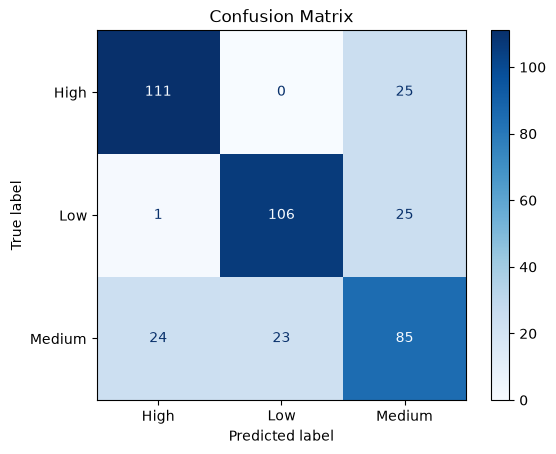

In [15]:
# confusion matrix :
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred =  best_models['Logistic Regression'].predict(x_test)
classes = best_models['Logistic Regression'].classes_
cm = confusion_matrix(y_test , y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm , display_labels=classes)

disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()


In [ ]:
# i will choose Logistic regression because it has More performance in 
# Accuracy , Precision recall and also F1 .  

In [9]:

# define the best model : 

pipeline = best_models["Logistic Regression"]

In [10]:
joblib.dump(model , "../model/best_model_pipeline.joblib")

['../model/best_model_pipeline.joblib']